# 01_eda

**Dueño:** Rol 1 · Datos

EDA de los pares work–award: tamaño, tasa de positivos, awards por publicación (techo de precision@3), cobertura de abstracts y descripciones, distribución por año y fuga temporal.

Solo se mira el **train** (publicaciones 2017–2024). El test (2025) no se abre hasta `05_seleccion`: de él solo se citan los conteos que trae el `manifest.json`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from scipy import stats
from sklearn.metrics import roc_auc_score

from src import contrato as C, datos, pipeline, tracking

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})
print("muestra de desarrollo" if datos.usar_muestra() else "datos reales", "|", C.EXPERIMENTO)

datos reales | grantmatch


## 1. Carga
`datos.cargar_pares('train')`; el test (2025) no se mira hasta `05_seleccion`. Los textos (abstracts, descripciones) pesan más de 1 GB en memoria, así que aquí se leen las columnas ligeras y el texto se revisa por bloques.

In [2]:
LIGERAS = [
    "work_key", "award_key", "label", "publication_year", "work_type", "cited_by_count", "authors_count", "fwci",
    "work_topic_key", "funder_name", "funder_country_code", "funding_type", "award_topic_key", "award_start_year",
    "duration_days", "institutions_count", "funded_outputs_count", "amount_usd", "has_description",
]
manifest = datos.leer_manifest()
pares = datos.cargar_pares("train", columnas=LIGERAS)
print(f"{len(pares):,} pares | {pares['work_key'].nunique():,} publicaciones | {pares['award_key'].nunique():,} awards distintos")
print("tabla de origen:", manifest["tabla_origen"], "| corte de la OBT:", manifest["fecha_corte"])
print("sha256 del snapshot:", manifest["sha256_obt_csv"][:16] + "...")
pares.dtypes.to_frame("tipo").T

804,250 pares | 39,474 publicaciones | 144,751 awards distintos
tabla de origen: OBT.OBT_AWARD_WORK | corte de la OBT: 2026-10-23 14:58:29.260618
sha256 del snapshot: ef2b43871376f294...


,work_key,award_key,label,publication_year,work_type,cited_by_count,authors_count,fwci,work_topic_key,funder_name,funder_country_code,funding_type,award_topic_key,award_start_year,duration_days,institutions_count,funded_outputs_count,amount_usd,has_description
tipo,object,object,int64,float64,object,int64,int64,float64,object,object,object,object,object,float64,float64,int64,int64,float64,bool


## 2. Tamaño, tipos y valores faltantes por columna
Los conteos de nulos salen de las estadísticas del parquet, sin cargar los textos.

804,250 filas x 57 columnas


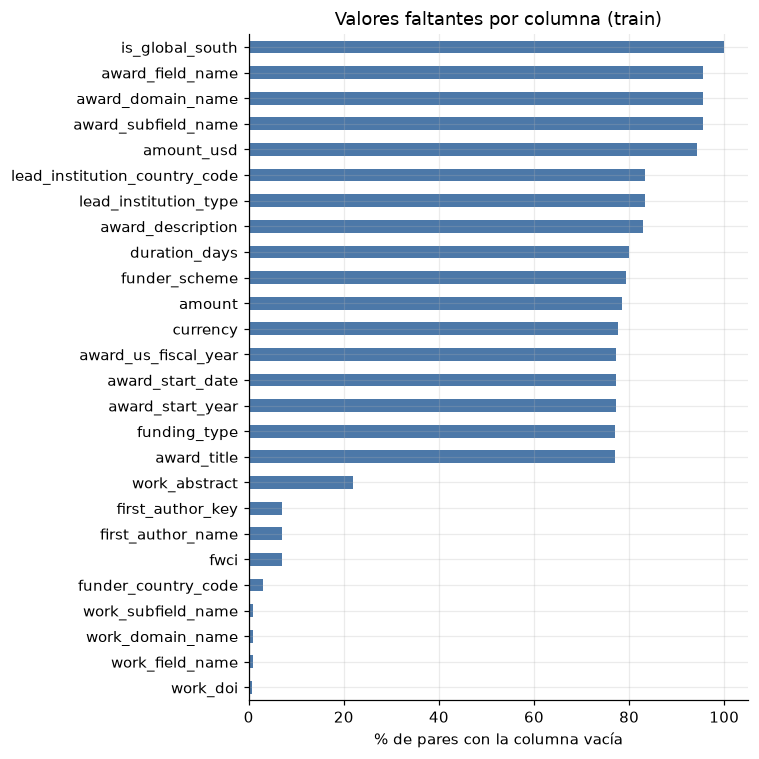

,is_global_south,award_subfield_name,award_field_name,award_domain_name,amount_usd,lead_institution_country_code,lead_institution_type,award_description,duration_days,funder_scheme,...,funding_type,work_abstract,first_author_key,fwci,first_author_name,funder_country_code,work_domain_name,work_field_name,work_subfield_name,work_doi
% vacío,100.0,95.6,95.6,95.6,94.3,83.4,83.3,82.9,79.9,79.3,...,77.0,21.9,7.0,7.0,7.0,3.0,0.9,0.9,0.9,0.7


In [3]:
pf = pq.ParquetFile(C.PARES_TRAIN)
nulos, total = {}, pf.metadata.num_rows
for g in range(pf.num_row_groups):
    grupo = pf.metadata.row_group(g)
    for j in range(grupo.num_columns):
        col = grupo.column(j)
        nulos[col.path_in_schema] = nulos.get(col.path_in_schema, 0) + (col.statistics.null_count if col.statistics else 0)
faltantes = pd.Series(nulos).div(total).mul(100).round(1).sort_values(ascending=False)
print(f"{total:,} filas x {pf.metadata.num_columns} columnas")
fig, ax = plt.subplots(figsize=(7, 7))
faltantes[faltantes > 0].sort_values().plot.barh(ax=ax, color="#4c78a8")
ax.set_xlabel("% de pares con la columna vacía"); ax.set_title("Valores faltantes por columna (train)")
plt.tight_layout(); plt.show()
faltantes[faltantes > 0].to_frame("% vacío").T

## 3. Target y desbalance

In [4]:
tasa = pares[C.TARGET].mean()
print(f"positivos: {pares[C.TARGET].sum():,} ({tasa:.1%}) | negativos: {(1 - pares[C.TARGET]).sum():,.0f} ({1 - tasa:.1%})")
print(f"Proporción por construcción: {C.NEGATIVOS_POR_POSITIVO} negativos por positivo -> 1 de cada {C.NEGATIVOS_POR_POSITIVO + 1} filas es positiva.")
print(f"Un ranking al azar acierta {tasa:.0%} en average precision y en precision@3: ese es el piso.")

tipos = pd.read_parquet(datos.NEGATIVOS_TIPO)
tipos = tipos[tipos["work_key"].isin(pares["work_key"].unique())]
print("\nNegativos por tipo:")
print(tipos["tipo"].value_counts().to_frame("negativos").assign(porcentaje=lambda t: (t["negativos"] / t["negativos"].sum() * 100).round(1)))
pd.DataFrame(manifest["negativos_dificiles_por_anio"]).assign(
    logrado=lambda t: (t["dificiles_logrados"] / t["dificiles_pedidos"] * 100).round(1)
)[["anio", "awards_vigentes", "publicaciones", "dificiles_pedidos", "dificiles_logrados", "logrado", "publicaciones_sin_dificiles"]]

positivos: 160,850 (20.0%) | negativos: 643,400 (80.0%)
Proporción por construcción: 4 negativos por positivo -> 1 de cada 5 filas es positiva.
Un ranking al azar acierta 20% en average precision y en precision@3: ese es el piso.



Negativos por tipo:
         negativos  porcentaje
tipo                          
azar        328028        51.0
dificil     315372        49.0


,anio,awards_vigentes,publicaciones,dificiles_pedidos,dificiles_logrados,logrado,publicaciones_sin_dificiles
0,2017,70874,2754,21004,20570,97.9,51
1,2018,83056,3254,24580,24145,98.2,50
2,2019,97358,3808,30298,29647,97.9,52
3,2020,110144,5061,39334,38455,97.8,59
4,2021,121399,5690,43824,43012,98.1,70
5,2022,114254,6017,54154,53241,98.3,65
6,2023,104543,6065,53584,52475,97.9,81
7,2024,91421,6825,54922,53827,98.0,86
8,2025,94616,7795,57584,55665,96.7,132


## 4. Awards por publicación: el techo de la precisión

Cada publicación tiene `n` awards positivos entre sus candidatos. Con un ranking perfecto, precision@3 vale `min(n, 3) / 3`: si una publicación solo tiene 1 award, ni el mejor modelo pasa de 0.33.

                          count  mean    std  min  25%  50%  75%     max
awards por publicación  39474.0  4.07  11.23  1.0  1.0  2.0  4.0  1609.0

Techo de precision@3 (ranking perfecto): 0.694
  publicaciones con 1 award: 36.0%
  publicaciones con 2 award: 19.9%
  publicaciones con 3 o más: 44.1%  (techo 1.0)

La publicación con más awards tiene 1,609; el 1 % de publicaciones con más awards concentra 14.2% de los positivos.


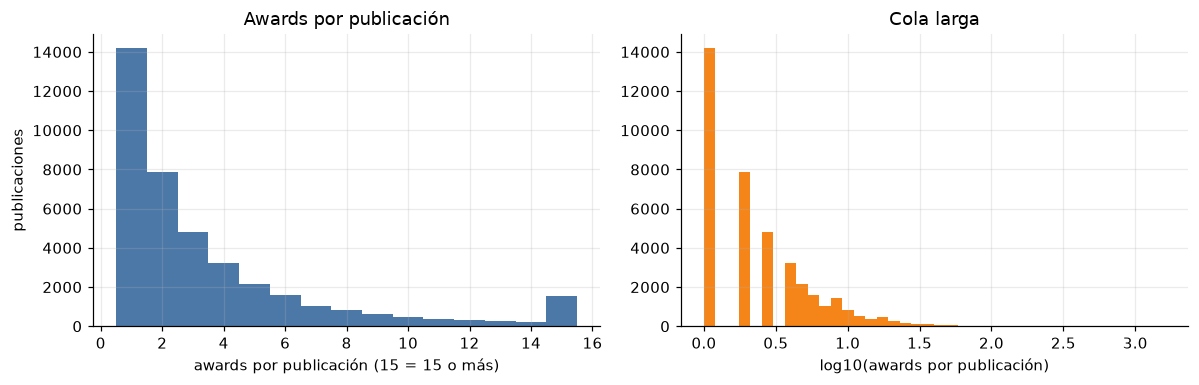

In [5]:
positivos = pares[pares[C.TARGET] == 1]
por_work = positivos.groupby(C.GRUPO).size()
techo = (por_work.clip(upper=C.K) / C.K)
print(por_work.describe().round(2).to_frame("awards por publicación").T)
print(f"\nTecho de precision@{C.K} (ranking perfecto): {techo.mean():.3f}")
for n in (1, 2):
    print(f"  publicaciones con {n} award: {(por_work == n).mean():.1%}")
print(f"  publicaciones con {C.K} o más: {(por_work >= C.K).mean():.1%}  (techo 1.0)")
top = por_work.sort_values(ascending=False)
print(f"\nLa publicación con más awards tiene {top.iloc[0]:,}; el 1 % de publicaciones con más awards concentra "
      f"{top.head(int(len(top) * 0.01)).sum() / top.sum():.1%} de los positivos.")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
ejes[0].hist(por_work.clip(upper=15), bins=np.arange(0.5, 16.5), color="#4c78a8")
ejes[0].set_xlabel("awards por publicación (15 = 15 o más)"); ejes[0].set_ylabel("publicaciones")
ejes[0].set_title("Awards por publicación")
ejes[1].hist(np.log10(por_work), bins=40, color="#f58518")
ejes[1].set_xlabel("log10(awards por publicación)"); ejes[1].set_title("Cola larga")
plt.tight_layout(); plt.show()

## 5. Cobertura de abstracts y descripciones
Los textos se revisan por bloques de 100 000 filas, por año de publicación.

In [6]:
import pyarrow.compute as pc

filas = []
for lote in pf.iter_batches(batch_size=100_000, columns=["publication_year", "work_abstract", "award_description", "award_title", "work_title"]):
    anio = lote.column("publication_year").to_numpy(zero_copy_only=False)
    validos = {c: lote.column(c).is_valid().to_numpy(zero_copy_only=False) for c in ["work_abstract", "award_description", "award_title", "work_title"]}
    largo = pc.fill_null(pc.utf8_length(lote.column("work_abstract")), 0).to_numpy(zero_copy_only=False)
    bloque = pd.DataFrame({"anio": anio, **validos, "largo_abstract": largo})
    filas.append(bloque.groupby("anio").agg(
        pares=("anio", "size"), con_abstract=("work_abstract", "sum"), con_descripcion_award=("award_description", "sum"),
        con_titulo_award=("award_title", "sum"), con_titulo_work=("work_title", "sum"), suma_largo=("largo_abstract", "sum"),
    ))
cobertura = pd.concat(filas).groupby(level=0).sum()
cobertura["% pares con abstract"] = (cobertura["con_abstract"] / cobertura["pares"] * 100).round(1)
cobertura["% con título de award"] = (cobertura["con_titulo_award"] / cobertura["pares"] * 100).round(1)
cobertura["% con descripción de award"] = (cobertura["con_descripcion_award"] / cobertura["pares"] * 100).round(1)
cobertura["largo medio del abstract"] = (cobertura["suma_largo"] / cobertura["con_abstract"]).round(0)
cobertura.index = cobertura.index.astype(int)
total_c = cobertura[["pares", "con_abstract", "con_descripcion_award", "con_titulo_award"]].sum()
print(f"Pares con abstract de la publicación: {total_c['con_abstract'] / total_c['pares']:.1%}")
print(f"Pares con título de award: {total_c['con_titulo_award'] / total_c['pares']:.1%} | con descripción: {total_c['con_descripcion_award'] / total_c['pares']:.1%}")
print("Cobertura (works y awards únicos):", manifest["cobertura_texto"])
cobertura[["pares", "% pares con abstract", "% con título de award", "% con descripción de award", "largo medio del abstract"]]

Pares con abstract de la publicación: 78.1%
Pares con título de award: 23.0% | con descripción: 17.1%
Cobertura (works y awards únicos): {'works_con_abstract': 33298, 'works_total': 47269, 'awards_con_descripcion': 24940, 'awards_en_pares': 163696}


,pares,% pares con abstract,% con título de award,% con descripción de award,largo medio del abstract
anio,,,,,
2017,52510,75.5,24.6,17.6,1372.0
2018,61450,75.3,24.0,17.2,1345.0
2019,75745,77.6,23.4,16.7,1342.0
2020,98335,75.0,22.2,16.3,1335.0
2021,109560,76.7,21.8,16.4,1368.0
2022,135385,82.6,21.9,16.7,1419.0
2023,133960,79.6,23.1,17.5,1380.0
2024,137305,77.9,24.0,18.5,1392.0


In [7]:
# Embeddings disponibles (all-MiniLM-L6-v2): solo hay fila para los works y awards que tienen texto
emb_w = pd.read_parquet(C.EMB_WORKS, columns=["work_key"])["work_key"]
emb_a = pd.read_parquet(C.EMB_AWARDS, columns=["award_key"])["award_key"]
print(f"Works con embedding: {pares['work_key'].drop_duplicates().isin(emb_w).mean():.1%}")
print(f"Awards con embedding: {pares['award_key'].drop_duplicates().isin(emb_a).mean():.1%}")
print(f"Pares donde ambos lados tienen embedding: {(pares['work_key'].isin(emb_w) & pares['award_key'].isin(emb_a)).mean():.1%}")

Works con embedding: 100.0%


Awards con embedding: 22.8%
Pares donde ambos lados tienen embedding: 23.0%


## 6. Distribución por año

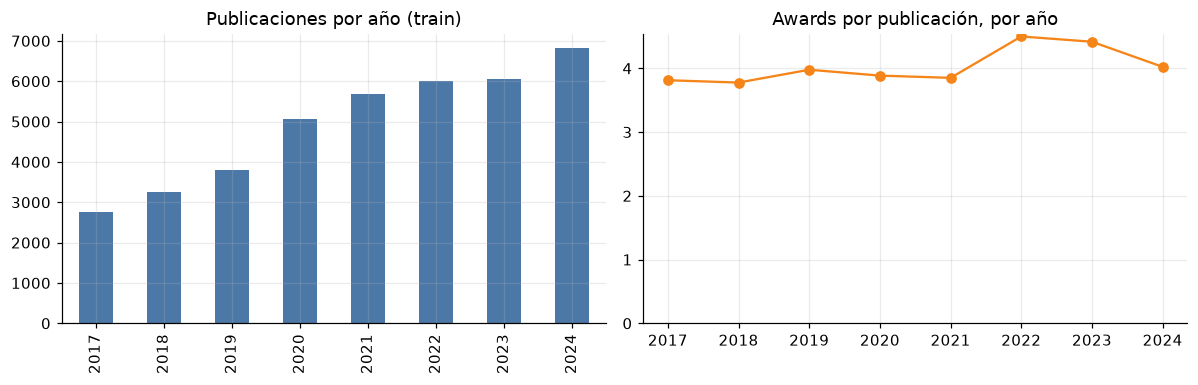

Test (2025), solo conteos: 143,960 pares, 28,792 positivos, 7,795 publicaciones


,pares,positivos,publicaciones
publication_year,,,
2017,52510,10502,2754
2018,61450,12290,3254
2019,75745,15149,3808
2020,98335,19667,5061
2021,109560,21912,5690
2022,135385,27077,6017
2023,133960,26792,6065
2024,137305,27461,6825


In [8]:
por_anio = pares.groupby("publication_year").agg(
    pares=("label", "size"), positivos=("label", "sum"), publicaciones=("work_key", "nunique"),
).astype(int)
por_anio.index = por_anio.index.astype(int)
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
por_anio["publicaciones"].plot.bar(ax=ejes[0], color="#4c78a8"); ejes[0].set_title("Publicaciones por año (train)"); ejes[0].set_xlabel("")
(por_anio["positivos"] / por_anio["publicaciones"]).plot(ax=ejes[1], marker="o", color="#f58518")
ejes[1].set_title("Awards por publicación, por año"); ejes[1].set_xlabel(""); ejes[1].set_ylim(0, None)
plt.tight_layout(); plt.show()
t = manifest["test"]
print(f"Test (2025), solo conteos: {t['filas']:,} pares, {t['positivos']:,} positivos, {t['publicaciones']:,} publicaciones")
por_anio

## 7. Estadística descriptiva y valores atípicos (IQR y Z-score)
Se describe cada publicación y cada award **una sola vez** (no una por par): si no, una publicación con 1 600 awards pesaría 1 600 veces.

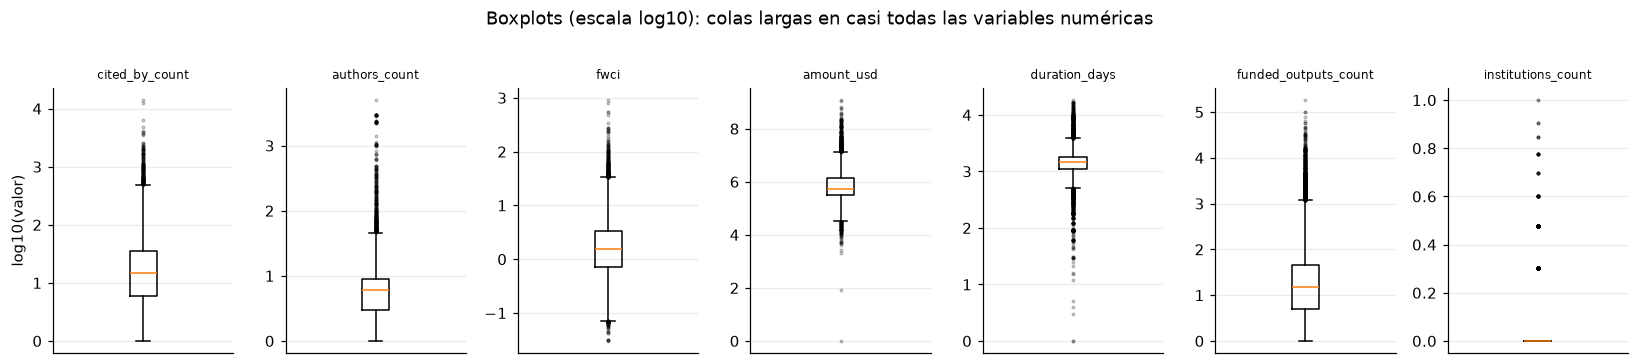

,nivel,columna,n,% vacío,media,mediana,máximo,asimetría,% atípicos IQR,% atípicos Z>=3
0,publicación,cited_by_count,39474,0.0,33.92,12.0000,1.404500e+04,50.7,9.8,0.6
1,publicación,authors_count,39474,0.0,10.21,6.0000,5.000000e+03,34.4,4.1,0.2
2,publicación,fwci,35863,9.1,3.24,1.4196,9.078113e+02,39.1,9.3,0.6
3,award,amount_usd,8080,94.4,3991892.38,540679.0000,1.196475e+09,27.2,14.9,0.6
4,award,duration_days,29293,79.8,1633.75,1460.0000,1.826200e+04,5.4,3.5,1.3
5,award,funded_outputs_count,144751,0.0,88.13,15.0000,1.823440e+05,90.8,12.5,0.3
6,award,institutions_count,144751,0.0,0.17,0.0000,1.000000e+01,2.8,16.8,0.6


In [9]:
works = pares.drop_duplicates(C.GRUPO)[["cited_by_count", "authors_count", "fwci"]]
awards = pares.drop_duplicates("award_key")[["amount_usd", "duration_days", "funded_outputs_count", "institutions_count"]]
resumen = []
for tabla, nombre in ((works, "publicación"), (awards, "award")):
    for col in tabla.columns:
        x = tabla[col].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        fuera_iqr = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean()
        fuera_z = (np.abs(stats.zscore(x)) >= 3).mean()
        resumen.append({"nivel": nombre, "columna": col, "n": len(x), "% vacío": round(tabla[col].isna().mean() * 100, 1),
                        "media": round(x.mean(), 2), "mediana": x.median(), "máximo": x.max(), "asimetría": round(x.skew(), 1),
                        "% atípicos IQR": round(fuera_iqr * 100, 1), "% atípicos Z>=3": round(fuera_z * 100, 1)})
resumen = pd.DataFrame(resumen)
fig, ejes = plt.subplots(1, 7, figsize=(15, 3.2))
for ax, (tabla, col) in zip(ejes, [(works, c) for c in works.columns] + [(awards, c) for c in awards.columns]):
    x = tabla[col].dropna()
    ax.boxplot(np.log10(x[x > 0]), flierprops={"markersize": 1.5, "alpha": 0.3})
    ax.set_title(col, fontsize=8); ax.set_xticks([])
ejes[0].set_ylabel("log10(valor)")
plt.suptitle("Boxplots (escala log10): colas largas en casi todas las variables numéricas", y=1.02)
plt.tight_layout(); plt.show()
resumen

## 8. Relación con el target: Spearman y AUC por variable
Se usa **Spearman** y no Pearson: las variables tienen colas muy largas y asimetría alta (tabla anterior), y Pearson se dejaría arrastrar por unos pocos valores extremos. El AUC de cada variable por separado dice cuánto separa positivos de negativos sin ningún modelo.

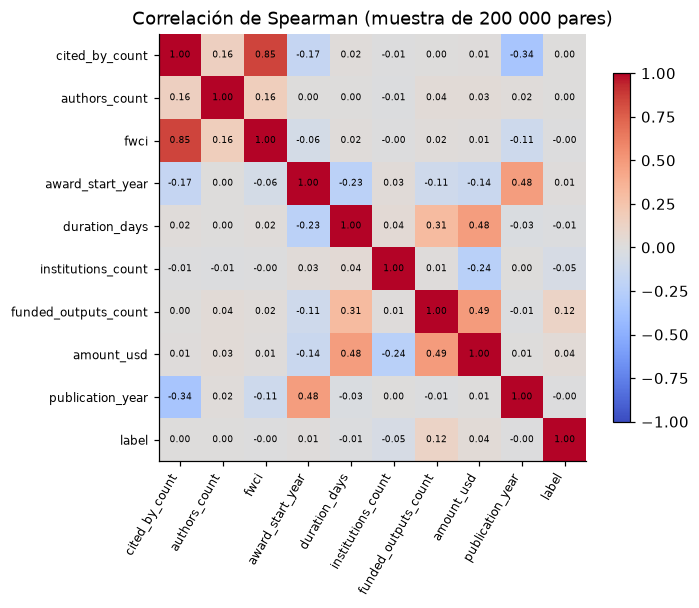

,AUC como puntaje,% vacío,|AUC - 0.5|
funded_outputs_count,0.586,0.0,0.086
institutions_count,0.478,0.0,0.022
award_start_year,0.499,77.2,0.001
amount_usd,0.501,94.3,0.001
duration_days,0.500,79.9,0.000
cited_by_count,0.500,0.0,0.000
fwci,0.500,7.0,0.000
authors_count,0.500,0.0,0.000
publication_year,0.500,0.0,0.000


In [10]:
numericas = ["cited_by_count", "authors_count", "fwci", "award_start_year", "duration_days", "institutions_count", "funded_outputs_count", "amount_usd", "publication_year"]
muestra = pares.sample(200_000, random_state=C.SEMILLA)
corr = muestra[numericas + [C.TARGET]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6)
ax.grid(False); plt.colorbar(im, shrink=0.8); ax.set_title("Correlación de Spearman (muestra de 200 000 pares)")
plt.tight_layout(); plt.show()

auc = pd.DataFrame({
    "AUC como puntaje": {c: roc_auc_score(pares[C.TARGET], pares[c].fillna(pares[c].median())) for c in numericas},
    "% vacío": {c: round(pares[c].isna().mean() * 100, 1) for c in numericas},
})
auc["|AUC - 0.5|"] = (auc["AUC como puntaje"] - 0.5).abs()
auc.sort_values("|AUC - 0.5|", ascending=False).round(3)

## 9. Positivos contra negativos: ¿hay atajos?
Si los negativos se distinguen de los positivos por algo que no tiene que ver con la pertinencia, el modelo lo aprende y las métricas salen infladas.

                         negativo (0)  positivo (1)
con_fecha_de_inicio             0.240         0.178
con_descripcion                 0.188         0.137
funder_en_US                    0.282         0.317
con_monto                       0.061         0.043
con_topic_award                 0.050         0.024
funded_outputs_mediana         16.000        25.000
funded_outputs_promedio       105.044      2563.414


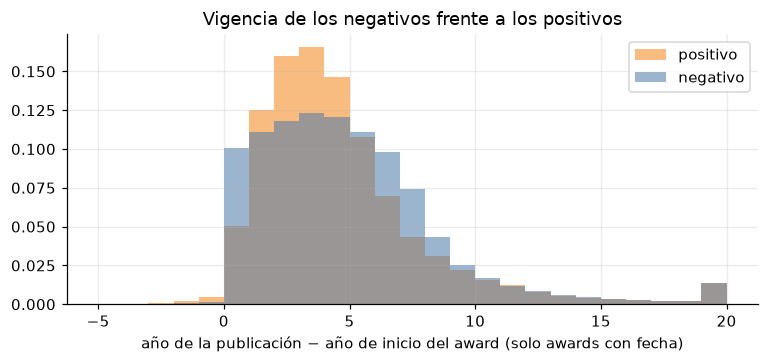

In [11]:
comparacion = pares.groupby(C.TARGET).agg(
    con_fecha_de_inicio=("award_start_year", lambda s: s.notna().mean()),
    con_descripcion=("has_description", "mean"),
    funder_en_US=("funder_country_code", lambda s: (s == "US").mean()),
    con_monto=("amount_usd", lambda s: s.notna().mean()),
    con_topic_award=("award_topic_key", lambda s: (s.notna() & (s != "UNKNOWN")).mean()),
    funded_outputs_mediana=("funded_outputs_count", "median"),
    funded_outputs_promedio=("funded_outputs_count", "mean"),
).T
comparacion.columns = ["negativo (0)", "positivo (1)"]
print(comparacion.round(3))

pares["anios_desde_inicio"] = pares["publication_year"] - pares["award_start_year"]
fig, ax = plt.subplots(figsize=(7, 3.4))
for valor, color in ((1, "#f58518"), (0, "#4c78a8")):
    x = pares.loc[pares[C.TARGET] == valor, "anios_desde_inicio"].dropna().clip(-5, 20)
    ax.hist(x, bins=np.arange(-5, 21), alpha=0.55, density=True, color=color, label="positivo" if valor else "negativo")
ax.set_xlabel("año de la publicación − año de inicio del award (solo awards con fecha)"); ax.legend(); ax.set_title("Vigencia de los negativos frente a los positivos")
plt.tight_layout(); plt.show()

## 10. Conclusiones para features y modelado

| Hallazgo | Evidencia | Consecuencia en el modelo |
|---|---|---|
| El techo de precision@3 es 0.69, no 1 | El 36.0 % de las publicaciones tiene un solo award y el 19.9 %, dos; solo el 44.1 % tiene 3 o más (techo `min(n, 3) / 3` = 0.694). Un ranking al azar da 0.20 | Los modelos se comparan entre 0.20 (piso) y 0.69 (techo): una diferencia de 0.02 es relevante en esa escala. Reportar siempre p@3 junto al techo |
| Unas pocas publicaciones pesan muchísimo | Mediana de 2 awards por publicación, máximo de 1 609. El 1 % de las publicaciones concentra el 14.2 % de los positivos y 8 045 de las 804 250 filas son de una sola | La validación agrupa por `work_key` (una publicación nunca se parte). Considerar pesos por publicación para que una de ellas no domine el entrenamiento. La métrica de negocio ya promedia por publicación |
| Casi toda la señal de texto está en la publicación, no en el award | El 78.1 % de los pares trae abstract, pero solo el 23.0 % trae título de award y el 17.1 %, descripción. Solo el 22.8 % de los awards tiene embedding: la similitud existe en el 23.0 % de los pares | Las features de similitud de embeddings van con un indicador de "award con texto" y un valor neutro cuando falta. El resto del modelo tiene que apoyarse en metadatos (funder, país, fechas) |
| `funded_outputs_count` es fuga, no una feature | Es el número de publicaciones que financió el award, incluida la de este par y las posteriores. AUC de 0.586 como puntaje único (mediana 25 en positivos contra 16 en negativos); las demás variables quedan entre 0.48 y 0.50 | No se usa como feature. Si se quiere "popularidad del award", se calcula solo con publicaciones anteriores al año del par, y dentro de cada fold |
| Colas muy largas | `cited_by_count`: asimetría de 50.7, 9.8 % de atípicos por IQR, máximo de 14 045. `amount_usd`: 94.4 % vacío, asimetría de 27.2. `authors_count`: máximo de 5 000 | Transformaciones logarítmicas o por rangos en las features numéricas, y Spearman en lugar de Pearson para medir relaciones |
| Los negativos no son idénticos a los positivos en metadatos | Positivos: 17.8 % de awards con fecha de inicio y 13.7 % con descripción; negativos: 24.0 % y 18.8 %. Los positivos favorecen awards muy productivos (mediana de 25 publicaciones contra 16), que suelen venir sin fechas ni descripción. Con topic conocido: 2.4 % de los positivos contra 5.0 % de los negativos | Las features que dependen de que el award tenga fecha, descripción o topic (`mismo_topic`, años desde el inicio) tienen una señal parcialmente artificial. Hay que mirar su importancia con cuidado y reportarlo en Limitaciones |

Otras decisiones que salen del EDA:

- **Desbalance:** 20 % de positivos por construcción (4 negativos por positivo). `average precision` sale con piso de 0.20; no hace falta reponderar clases.
- **Vigencia:** solo alrededor del 18 % de los awards trae fechas, así que la vigencia de los demás se infiere de sus publicaciones observadas (ver el docstring de `datos._ventanas`). Los negativos de train usan solo publicaciones hasta 2024.
- **Dificultad de los negativos:** el 49.0 % de los negativos son difíciles (mismo país del funder en casi todos; el mismo topic solo en el 5 % de los intentos, porque solo el 2.4 % de los positivos trae topic de award). El 98 % de los difíciles pedidos se logró.
- **Año:** las publicaciones por año crecen de 2 754 (2017) a 6 825 (2024) y los awards por publicación pasan de 3.8 a 4.0 con un salto a 4.5 en 2022 y 2023. Hay deriva temporal: el test de 2025 (7 795 publicaciones) es la prueba justa.